# 01 — Model V2 Data Exploration & Cricket Accounting Audit

Exploratory analysis built strictly on the verified `src/model_v2/` Phase 1 foundation modules:
- Competition & match scope (`837` primary matches: `367` IPL + `470` T20I; `193,988` deliveries; `185,692` legal balls)
- Cricket accounting rules, `playing_eleven` deduplication, and `player_id` homonym isolation
- Season-by-season and phase-by-phase scoring inflation across `IPL`, `T20I_Full`, and `T20I_Assoc`
- Dynamic batting roles (`Top 1-3`, `Middle 4-5`, `Finisher 6+`) and bowling archetypes (`pace_or_spin`, `bowling_style_group`)

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / 'src' / 'model_v2').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.model_v2.data_loader import load_clean_dataset, load_raw_tables
from src.model_v2.state_builder import assign_phase
from src.model_v2.batting_features import add_batting_features, summarize_batter_roles
from src.model_v2.bowling_features import add_bowling_features, summarize_bowler_styles

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')

## 1. Scope Reconciliation: Full Raw vs Primary V2 Scope

In [2]:
raw = load_raw_tables()
bbb_all, matches_all, pe_all, pl_all = load_clean_dataset(include_other_t20=True, include_super_overs=True)
bbb, matches, pe, pl = load_clean_dataset(include_other_t20=False, include_super_overs=False)

scope_summary = pd.DataFrame([
    {'Scope': 'Raw ball_by_ball.csv', 'Matches': raw['ball_by_ball']['match_id'].nunique(), 'Deliveries': len(raw['ball_by_ball']), 'Legal_Balls': int((~raw['ball_by_ball']['extras_type'].isin(['wide', 'Overstep', 'other'])).sum())},
    {'Scope': 'Excluded: Other_T20 (comp_id 2670, 3289)', 'Matches': int(bbb_all.loc[bbb_all['comp_category']=='Other_T20', 'match_id'].nunique()), 'Deliveries': int((bbb_all['comp_category']=='Other_T20').sum()), 'Legal_Balls': int(bbb_all.loc[bbb_all['comp_category']=='Other_T20', 'is_legal_ball'].sum())},
    {'Scope': 'Excluded: Super Overs (innings 3-4, IPL+T20I)', 'Matches': int(bbb_all.loc[(bbb_all['comp_category']!='Other_T20') & (bbb_all['innings'].isin([3,4])), 'match_id'].nunique()), 'Deliveries': int(((bbb_all['comp_category']!='Other_T20') & (bbb_all['innings'].isin([3,4]))).sum()), 'Legal_Balls': int(bbb_all.loc[(bbb_all['comp_category']!='Other_T20') & (bbb_all['innings'].isin([3,4])), 'is_legal_ball'].sum())},
    {'Scope': 'Primary V2 Scope (IPL + T20I, Inn 1-2)', 'Matches': int(matches['match_id'].nunique()), 'Deliveries': len(bbb), 'Legal_Balls': int(bbb['is_legal_ball'].sum())},
])
print(scope_summary.to_string(index=False))
print('\nPrimary matches by comp_tier:')
print(matches['comp_tier'].value_counts().to_frame('matches'))
print(f'\nplaying_eleven raw={len(raw["playing_eleven"])}, deduplicated={len(pe)} (removed {len(raw["playing_eleven"])-len(pe)} duplicate keys)')

                                        Scope  Matches  Deliveries  Legal_Balls
                         Raw ball_by_ball.csv      867      200999       192445
     Excluded: Other_T20 (comp_id 2670, 3289)       30        6985         6730
Excluded: Super Overs (innings 3-4, IPL+T20I)        4          26           23
       Primary V2 Scope (IPL + T20I, Inn 1-2)      837      193988       185692

Primary matches by comp_tier:
            matches
comp_tier          
T20I_Full       417
IPL             367
T20I_Assoc       53

playing_eleven raw=28381, deduplicated=28341 (removed 40 duplicate keys)


## 2. Cricket Accounting, Dismissal Normalization & Player Homonyms

In [3]:
extras_tbl = bbb.groupby('extras_type', dropna=False).agg(
    deliveries=('runs', 'count'),
    legal_balls=('is_legal_ball', 'sum'),
    batter_balls_faced=('is_batter_ball_faced', 'sum'),
    total_runs=('total_runs', 'sum'),
    bowler_runs_conceded=('bowler_runs_conceded', 'sum'),
).reset_index()
print('Extras & delivery accounting (Primary Scope):')
print(extras_tbl.to_string(index=False))

wkt_tbl = bbb[bbb['is_team_wicket']].groupby('dismissal_type', dropna=False).agg(
    team_wickets=('is_team_wicket', 'sum'),
    bowler_wickets=('is_bowler_wicket', 'sum'),
    striker_dismissed=('is_striker_dismissed', 'sum'),
).reset_index()
print('\nDismissal accounting (Primary Scope):')
print(wkt_tbl.to_string(index=False))

homonyms = pl[pl['player_name'].isin(['Abdul Samad', 'Rashid Khan', 'Haider Ali'])].sort_values(['player_name', 'player_id'])
print('\nHomonym player_id verification:')
print(homonyms.to_string(index=False))

Extras & delivery accounting (Primary Scope):
extras_type  deliveries  legal_balls  batter_balls_faced  total_runs  bowler_runs_conceded
   Overstep         565            0                 565        1447                  1399
    Penalty           1            1                   1           5                     0
       byes         505          505                 505         960                     0
    legbyes        2661         2661                2661        3500                     0
      other         259            0                 259         700                   666
       wide        7472            0                   0        8880                  8880
        NaN      182525       182525              182525      259843                259841

Dismissal accounting (Primary Scope):
       dismissal_type  team_wickets  bowler_wickets  striker_dismissed
               Bowled          1689            1689               1689
               Caught          7327          

## 3. IPL vs T20I Scoring Inflation & Phase Baselines (2022–2026)

 comp_tier  season_year  matches  rpo  bnd_pct  dot_pct  balls_per_wkt
       IPL         2022       74 8.54    17.97    38.70          18.81
       IPL         2023       74 8.99    19.24    35.60          18.75
       IPL         2024       71 9.56    21.07    34.54          18.46
       IPL         2025       74 9.63    21.55    33.79          19.00
       IPL         2026       74 9.88    22.55    34.12          19.00
T20I_Assoc         2022       12 7.82    14.54    38.79          17.61
T20I_Assoc         2023        3 7.60    13.44    37.28          17.74
T20I_Assoc         2024       14 7.99    15.22    39.86          15.81
T20I_Assoc         2025       21 7.93    15.35    42.19          16.84
T20I_Assoc         2026        3 7.47    13.73    41.93          14.18
 T20I_Full         2022       94 8.42    17.03    37.53          18.03
 T20I_Full         2023       63 8.60    17.87    37.55          17.30
 T20I_Full         2024       92 8.58    17.96    39.07          16.51
 T20I_

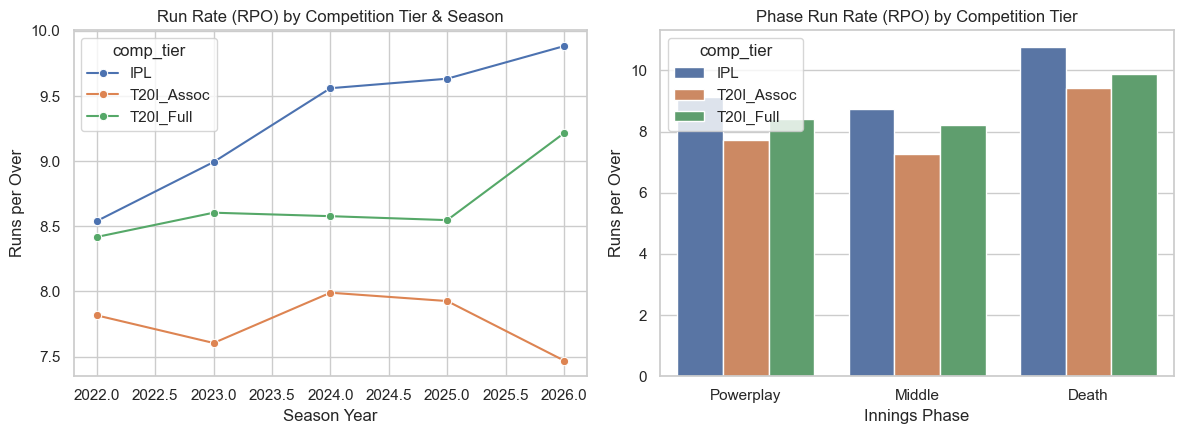

In [4]:
bbb['phase'] = assign_phase(bbb['overid'])
season_trends = (
    bbb.groupby(['comp_tier', 'season_year'])
    .agg(
        matches=('match_id', 'nunique'),
        legal_balls=('is_legal_ball', 'sum'),
        runs=('total_runs', 'sum'),
        wkts=('is_team_wicket', 'sum'),
        bnds=('is_boundary_bat', 'sum'),
        dots=('is_dot_bowl', 'sum'),
    )
    .assign(
        rpo=lambda d: 6.0 * d['runs'] / d['legal_balls'],
        bnd_pct=lambda d: 100.0 * d['bnds'] / d['legal_balls'],
        dot_pct=lambda d: 100.0 * d['dots'] / d['legal_balls'],
        balls_per_wkt=lambda d: d['legal_balls'] / d['wkts'],
    )
    .reset_index()
)
print(season_trends[['comp_tier', 'season_year', 'matches', 'rpo', 'bnd_pct', 'dot_pct', 'balls_per_wkt']].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.lineplot(data=season_trends, x='season_year', y='rpo', hue='comp_tier', marker='o', ax=axes[0])
axes[0].set_title('Run Rate (RPO) by Competition Tier & Season')
axes[0].set_ylabel('Runs per Over')
axes[0].set_xlabel('Season Year')

phase_rates = (
    bbb.groupby(['comp_tier', 'phase'])
    .agg(runs=('total_runs', 'sum'), legal=('is_legal_ball', 'sum'))
    .assign(rpo=lambda d: 6.0 * d['runs'] / d['legal'])
    .reset_index()
)
sns.barplot(data=phase_rates, x='phase', y='rpo', hue='comp_tier', order=['Powerplay', 'Middle', 'Death'], ax=axes[1])
axes[1].set_title('Phase Run Rate (RPO) by Competition Tier')
axes[1].set_ylabel('Runs per Over')
axes[1].set_xlabel('Innings Phase')
plt.tight_layout()
plt.show()

## 4. Dynamic Batting Roles & Bowling Style Distribution

In [5]:
df_feat = add_bowling_features(add_batting_features(bbb, pe))
role_phase = (
    df_feat[df_feat['is_batter_ball_faced']]
    .groupby(['batting_role', 'phase'])
    .agg(balls=('runs', 'count'), runs=('runs', 'sum'), outs=('is_striker_dismissed', 'sum'))
    .assign(sr=lambda d: 100.0 * d['runs'] / d['balls'], out_pct=lambda d: 100.0 * d['outs'] / d['balls'])
    .reset_index()
)
print('Batting role x phase scoring profile:')
print(role_phase.round(2).to_string(index=False))
print(f"\nRole mismatch deliveries: {int(df_feat['is_role_mismatch'].sum())}, uncertain (mismatch or missing PE): {int(df_feat['is_role_uncertain'].sum())}")

bowl_phase = (
    df_feat.groupby(['pace_or_spin', 'phase'])
    .agg(legal_balls=('is_legal_ball', 'sum'), conceded=('bowler_runs_conceded', 'sum'), wkts=('is_bowler_wicket', 'sum'))
    .assign(er=lambda d: 6.0 * d['conceded'] / d['legal_balls'], sr=lambda d: d['legal_balls'] / d['wkts'])
    .reset_index()
)
print('\nBowling pace/spin x phase profile:')
print(bowl_phase.round(2).to_string(index=False))

Batting role x phase scoring profile:
batting_role     phase  balls  runs  outs     sr  out_pct
 Finisher 6+     Death  24565 36000  2203 146.55     8.97
 Finisher 6+    Middle  18273 20574   952 112.59     5.21
 Finisher 6+ Powerplay    506   477    11  94.27     2.17
  Middle 4-5     Death  10799 19233   759 178.10     7.03
  Middle 4-5    Middle  32162 42665  1452 132.66     4.51
  Middle 4-5 Powerplay   7212  8386   276 116.28     3.83
     Top 1-3     Death   5183  9570   371 184.64     7.16
     Top 1-3    Middle  35997 52180  1731 144.96     4.81
     Top 1-3 Powerplay  51819 71997  2427 138.94     4.68

Role mismatch deliveries: 255, uncertain (mismatch or missing PE): 358

Bowling pace/spin x phase profile:
pace_or_spin     phase  legal_balls  conceded  wkts    er    sr
        Pace     Death        32050     55446  2472 10.38 12.97
        Pace    Middle        34404     50864  1700  8.87 20.24
        Pace Powerplay        47430     67794  2146  8.58 22.10
        Spin     D